# RB/FB current-week Waiver features

## tl;dr

This notebook creates the current-week `gold_rb_weekly_trends` foundation at one row per `player_id + season + week` for the 2023–2025 regular seasons.

The executed output contains **5,542 player-weeks and 99 columns** across three season partitions. It retains **687 rows without weekly-stat evidence** while preserving confirmed zero canonical opportunity. All grain, total-reconciliation, ratio, scoring, null-behavior, schema, dtype, season, and Parquet round-trip checks pass.

Rolling windows, eligibility rules, comparisons, and waiver signals are intentionally deferred until this current-week contract is reviewed.

## Context & Methods

### Scope

- Seasons: 2023–2025
- Season type: regular season only
- Output grain: `player_id + season + week`
- Default scoring: full PPR
- Rolling features: deliberately out of scope for this checkpoint

This notebook establishes the current-week Waiver Gold contract. It retains every regular-season contextual player-week from the RB/FB Silver facts facts, including rows without weekly-stat evidence. It does not manufacture roster-only or bye-week rows.

### Key assumptions

- An NFL week is the calendar-week unit that future rolling features will use.
- Current Silver data has at most one team record per player-week. The aggregation is nevertheless future-safe: all game, team, and opponent identifiers are retained as ordered text, while singular `team` and `opponent_team` are null if a future week contains more than one value.
- Canonical PBP opportunity remains observed zero when complete play evidence supports zero. Nullable official weekly statistics remain null when no stat record exists.
- Shares and efficiencies are recomputed from their component totals; weekly percentages are never averaged.
- A zero denominator produces null. A zero numerator with a valid denominator produces zero.
- Rolling windows, history eligibility, comparisons, and signals will be added only after these current-week outputs are reviewed.

## Data

### 1. Set up paths, grain, and feature groups

The output order is declared before transformation so the persisted schema is explicit and testable.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


SEASONS = [2023, 2024, 2025, 2026]
SILVER_GRAIN = ["player_id", "season", "week", "team"]
GOLD_GRAIN = ["player_id", "season", "week"]

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "ROADMAP.md").exists():
    for parent in PROJECT_ROOT.parents:
        if (parent / "ROADMAP.md").exists():
            PROJECT_ROOT = parent
            break
    else:
        raise RuntimeError("Could not locate the repository root.")

SILVER_INPUT_DIR = PROJECT_ROOT / "data/silver/rb_week"
GOLD_OUTPUT_DIR = PROJECT_ROOT / "data/gold/waiver/rb_weekly_trends"

RB_INPUT_COLUMNS = [
    "player_id", "game_id", "season", "week", "season_type", "team",
    "opponent_team", "display_name", "stats_position", "snap_position",
    "has_stat_record", "has_snap_record", "participated_game",
    "offensive_participant", "offense_snaps", "rushing_attempts",
    "rushing_yards", "rushing_touchdowns", "rushing_first_downs",
    "rushing_2pt_conversions", "receiving_targets", "receptions",
    "receiving_yards", "receiving_touchdowns", "receiving_air_yards",
    "receiving_yards_after_catch", "receiving_first_downs",
    "receiving_2pt_conversions", "fumbles", "fumbles_lost",
    "special_teams_touchdowns", "pbp_rush_attempts",
    "pbp_non_kneel_rush_attempts", "pbp_designed_rush_attempts", "pbp_targets",
    "pbp_target_air_yards", "red_zone_rush_attempts", "goal_line_rush_attempts",
    "red_zone_targets", "goal_line_targets", "end_zone_targets", "team_targets",
    "team_air_yards", "team_non_kneel_rush_attempts", "team_designed_rush_attempts",
    "team_red_zone_targets", "team_goal_line_targets", "team_end_zone_targets",
    "team_red_zone_rush_attempts", "team_goal_line_rush_attempts",
    "team_rb_rushing_attempts", "team_rb_red_zone_rush_attempts",
    "team_rb_goal_line_rush_attempts",
]

IDENTITY_COLUMNS = [
    "player_id", "season", "week", "display_name", "position",
    "positions_observed", "game_ids", "teams_in_week", "team_count", "team",
    "opponents_in_week", "opponent_team",
]
PARTICIPATION_COLUMNS = [
    "games_observed", "games_with_stat_record", "games_with_snap_record",
    "games_participated", "games_offensive_participant", "offense_snaps",
    "offense_snaps_per_game",
]
PRODUCTION_OPPORTUNITY_COLUMNS = [
    "official_opportunities", "total_opportunities", "touches", "rushing_attempts",
    "non_kneel_rush_attempts", "designed_rush_attempts", "rushing_yards",
    "rushing_touchdowns", "rushing_first_downs", "rushing_2pt_conversions",
    "targets", "receptions", "receiving_yards", "receiving_touchdowns",
    "receiving_first_downs", "receiving_2pt_conversions", "receiving_air_yards",
    "receiving_yards_after_catch", "scrimmage_yards", "total_touchdowns",
    "fumbles", "fumbles_lost", "special_teams_touchdowns",
    "red_zone_rush_attempts", "goal_line_rush_attempts", "red_zone_targets",
    "goal_line_targets", "end_zone_targets",
]
TEAM_DENOMINATOR_COLUMNS = [
    "team_targets", "team_target_air_yards", "team_non_kneel_rush_attempts",
    "team_designed_rush_attempts", "team_red_zone_targets",
    "team_goal_line_targets", "team_end_zone_targets", "team_red_zone_rush_attempts",
    "team_goal_line_rush_attempts", "team_rb_rushing_attempts",
    "team_rb_red_zone_rush_attempts", "team_rb_goal_line_rush_attempts",
]
SHARE_COLUMNS = [
    "rush_attempt_share", "backfield_rush_share", "backfield_red_zone_rush_share",
    "backfield_goal_line_rush_share", "designed_rush_share", "red_zone_rush_share",
    "goal_line_rush_share", "target_share", "target_air_yards_share",
    "red_zone_target_share", "goal_line_target_share", "end_zone_target_share",
]
EFFICIENCY_COLUMNS = [
    "rushing_yards_per_attempt", "rushing_first_down_rate", "rushing_touchdown_rate",
    "catch_rate", "receiving_yards_per_target", "receiving_yards_per_reception",
    "average_depth_of_target", "yards_after_catch_per_reception",
    "receiving_first_down_rate", "receiving_touchdown_rate",
    "scrimmage_yards_per_opportunity", "ppr_fantasy_points_per_opportunity",
]
PER_GAME_COLUMNS = [
    "official_opportunities_per_game", "total_opportunities_per_game",
    "touches_per_game", "rushing_attempts_per_game", "targets_per_game",
    "receptions_per_game", "rushing_yards_per_game", "receiving_yards_per_game",
    "scrimmage_yards_per_game", "total_touchdowns_per_game",
    "ppr_fantasy_points_per_game",
]
FANTASY_POINT_COLUMNS = [
    "receiving_fantasy_points", "rushing_fantasy_points",
    "special_teams_fantasy_points", "fumble_lost_points", "ppr_fantasy_points",
]
GOLD_COLUMNS = [
    *IDENTITY_COLUMNS, *PARTICIPATION_COLUMNS, *PRODUCTION_OPPORTUNITY_COLUMNS,
    *TEAM_DENOMINATOR_COLUMNS, *SHARE_COLUMNS, *EFFICIENCY_COLUMNS,
    *PER_GAME_COLUMNS, *FANTASY_POINT_COLUMNS,
]

assert len(RB_INPUT_COLUMNS) == 53
assert len(GOLD_COLUMNS) == 99
assert len(GOLD_COLUMNS) == len(set(GOLD_COLUMNS))
pd.set_option("display.max_columns", 105)

### 2. Define calculation contracts

The contracts expose every share, efficiency, per-game denominator, and scoring choice before calculation.

In [2]:
share_contract = pd.DataFrame(
    [
        ["rush_attempt_share", "non_kneel_rush_attempts", "team_non_kneel_rush_attempts"],
        ["backfield_rush_share", "rushing_attempts", "team_rb_rushing_attempts"],
        ["backfield_red_zone_rush_share", "red_zone_rush_attempts", "team_rb_red_zone_rush_attempts"],
        ["backfield_goal_line_rush_share", "goal_line_rush_attempts", "team_rb_goal_line_rush_attempts"],
        ["designed_rush_share", "designed_rush_attempts", "team_designed_rush_attempts"],
        ["red_zone_rush_share", "red_zone_rush_attempts", "team_red_zone_rush_attempts"],
        ["goal_line_rush_share", "goal_line_rush_attempts", "team_goal_line_rush_attempts"],
        ["target_share", "targets", "team_targets"],
        ["target_air_yards_share", "receiving_air_yards", "team_target_air_yards"],
        ["red_zone_target_share", "red_zone_targets", "team_red_zone_targets"],
        ["goal_line_target_share", "goal_line_targets", "team_goal_line_targets"],
        ["end_zone_target_share", "end_zone_targets", "team_end_zone_targets"],
    ],
    columns=["feature", "numerator", "denominator"],
)

efficiency_contract = pd.DataFrame(
    [
        ["rushing_yards_per_attempt", "rushing_yards", "rushing_attempts"],
        ["rushing_first_down_rate", "rushing_first_downs", "rushing_attempts"],
        ["rushing_touchdown_rate", "rushing_touchdowns", "rushing_attempts"],
        ["catch_rate", "receptions", "targets"],
        ["receiving_yards_per_target", "receiving_yards", "targets"],
        ["receiving_yards_per_reception", "receiving_yards", "receptions"],
        ["average_depth_of_target", "receiving_air_yards", "targets"],
        ["yards_after_catch_per_reception", "receiving_yards_after_catch", "receptions"],
        ["receiving_first_down_rate", "receiving_first_downs", "receptions"],
        ["receiving_touchdown_rate", "receiving_touchdowns", "targets"],
        ["scrimmage_yards_per_opportunity", "scrimmage_yards", "total_opportunities"],
    ],
    columns=["feature", "numerator", "denominator"],
)

PER_GAME_DEFINITIONS = {
    "offense_snaps_per_game": ("offense_snaps", "games_observed"),
    "official_opportunities_per_game": ("official_opportunities", "games_observed"),
    "total_opportunities_per_game": ("total_opportunities", "games_observed"),
    "touches_per_game": ("touches", "games_observed"),
    "rushing_attempts_per_game": ("rushing_attempts", "games_observed"),
    "targets_per_game": ("targets", "games_observed"),
    "receptions_per_game": ("receptions", "games_observed"),
    "rushing_yards_per_game": ("rushing_yards", "games_observed"),
    "receiving_yards_per_game": ("receiving_yards", "games_observed"),
    "scrimmage_yards_per_game": ("scrimmage_yards", "games_observed"),
    "total_touchdowns_per_game": ("total_touchdowns", "games_observed"),
}

scoring_contract = pd.DataFrame(
    [
        ["reception", 1.0], ["receiving yard", 0.1],
        ["receiving touchdown", 6.0], ["rushing yard", 0.1],
        ["rushing touchdown", 6.0], ["two-point conversion", 2.0],
        ["fumble lost", -2.0], ["special-teams touchdown", 6.0],
    ],
    columns=["event", "full_ppr_points"],
)

display(share_contract)
display(efficiency_contract)
scoring_contract

,feature,numerator,denominator
0,rush_attempt_share,non_kneel_rush_attempts,team_non_kneel_rush_attempts
1,backfield_rush_share,rushing_attempts,team_rb_rushing_attempts
2,backfield_red_zone_rush_share,red_zone_rush_attempts,team_rb_red_zone_rush_attempts
3,backfield_goal_line_rush_share,goal_line_rush_attempts,team_rb_goal_line_rush_attempts
4,designed_rush_share,designed_rush_attempts,team_designed_rush_attempts
5,red_zone_rush_share,red_zone_rush_attempts,team_red_zone_rush_attempts
6,goal_line_rush_share,goal_line_rush_attempts,team_goal_line_rush_attempts
7,target_share,targets,team_targets
8,target_air_yards_share,receiving_air_yards,team_target_air_yards
9,red_zone_target_share,red_zone_targets,team_red_zone_targets


,feature,numerator,denominator
0,rushing_yards_per_attempt,rushing_yards,rushing_attempts
1,rushing_first_down_rate,rushing_first_downs,rushing_attempts
2,rushing_touchdown_rate,rushing_touchdowns,rushing_attempts
3,catch_rate,receptions,targets
4,receiving_yards_per_target,receiving_yards,targets
5,receiving_yards_per_reception,receiving_yards,receptions
6,average_depth_of_target,receiving_air_yards,targets
7,yards_after_catch_per_reception,receiving_yards_after_catch,receptions
8,receiving_first_down_rate,receiving_first_downs,receptions
9,receiving_touchdown_rate,receiving_touchdowns,targets


,event,full_ppr_points
0,reception,1.0
1,receiving yard,0.1
2,receiving touchdown,6.0
3,rushing yard,0.1
4,rushing touchdown,6.0
5,two-point conversion,2.0
6,fumble lost,-2.0
7,special-teams touchdown,6.0


### 3. Load the RB/FB Silver partitions

In [3]:
silver_paths = sorted(SILVER_INPUT_DIR.glob("*.parquet"))
assert len(silver_paths) == len(SEASONS)

source_facts = pd.concat(
    [pd.read_parquet(path, columns=RB_INPUT_COLUMNS) for path in silver_paths],
    ignore_index=True,
)

input_summary = pd.DataFrame(
    [["silver_rb_week", len(source_facts), 68,
      len(source_facts.columns), len(silver_paths)]],
    columns=["input", "rows", "columns_available", "columns_selected", "files"],
)

assert set(source_facts["season"].unique()) == set(SEASONS)
input_summary

,input,rows,columns_available,columns_selected,files
0,silver_rb_week,6362,68,53,4


## Results

### 4. Validate the input grain and select regular-season observations

Postseason facts remain in Silver but do not enter the Waiver Gold foundation.

In [4]:
assert source_facts[SILVER_GRAIN].notna().all().all()
assert not source_facts.duplicated(SILVER_GRAIN).any()

regular_facts = (
    source_facts.loc[source_facts["season_type"].eq("REG")]
    .sort_values(["player_id", "season", "week", "team", "game_id"])
    .reset_index(drop=True)
)

assert regular_facts["game_id"].notna().all()
assert not regular_facts.duplicated(SILVER_GRAIN).any()
assert not regular_facts.duplicated(["player_id", "season", "game_id"]).any()

regular_population_summary = (
    regular_facts.groupby("season", dropna=False)
    .agg(
        silver_rows=("player_id", "size"),
        player_weeks=("player_id", lambda values: regular_facts.loc[values.index, GOLD_GRAIN].drop_duplicates().shape[0]),
        players=("player_id", "nunique"),
        teams=("team", "nunique"),
        weeks=("week", "nunique"),
    )
    .reset_index()
)
regular_population_summary

,season,silver_rows,player_weeks,players,teams,weeks
0,2023,1847,1847,167,32,18
1,2024,1849,1849,164,32,18
2,2025,1846,1846,167,32,18
3,2026,536,536,134,32,5


### 5. Build player-week identity and team context

Ordered context fields preserve all observed values. Singular team and opponent fields are populated only when the player-week has one distinct value.

In [5]:
def sum_with_minimum_evidence(values):
    return values.sum(min_count=1)


def count_confirmed_true(values):
    return values.fillna(False).sum()


def ordered_unique_text(values):
    observed = [str(value) for value in values.dropna() if str(value)]
    return ", ".join(dict.fromkeys(observed))


def only_observed_value(values):
    observed = list(dict.fromkeys(str(value) for value in values.dropna()))
    return observed[0] if len(observed) == 1 else pd.NA


weekly_context = (
    regular_facts.groupby(GOLD_GRAIN, sort=False, dropna=False)
    .agg(
        display_name=("display_name", "last"),
        game_ids=("game_id", ordered_unique_text),
        teams_in_week=("team", ordered_unique_text),
        team_count=("team", "nunique"),
        team=("team", only_observed_value),
        opponents_in_week=("opponent_team", ordered_unique_text),
        opponent_team=("opponent_team", only_observed_value),
    )
    .reset_index()
)

assert not weekly_context.duplicated(GOLD_GRAIN).any()
assert weekly_context["display_name"].notna().all()
assert weekly_context["game_ids"].ne("").all()
assert weekly_context.loc[weekly_context["team_count"].eq(1), "team"].notna().all()
assert weekly_context.loc[weekly_context["team_count"].gt(1), "team"].isna().all()



position_evidence = regular_facts[
    GOLD_GRAIN + ["stats_position", "snap_position"]
].melt(
    id_vars=GOLD_GRAIN,
    value_vars=["stats_position", "snap_position"],
    value_name="observed_position",
)
position_evidence = position_evidence.loc[
    position_evidence["observed_position"].notna()
]

weekly_positions = (
    position_evidence.groupby(GOLD_GRAIN, sort=False)["observed_position"]
    .agg(ordered_unique_text)
    .rename("positions_observed")
    .reset_index()
)

weekly_context = weekly_context.merge(
    weekly_positions,
    on=GOLD_GRAIN,
    how="left",
    validate="one_to_one",
)
weekly_context["position"] = weekly_context["positions_observed"].where(
    ~weekly_context["positions_observed"].str.contains(",", na=False),
    "RB/FB",
)
weekly_context["position"] = weekly_context["position"].fillna("RB/FB")

assert weekly_context["positions_observed"].notna().all()
assert weekly_context["position"].notna().all()


weekly_context.head()

,player_id,season,week,display_name,game_ids,teams_in_week,team_count,team,opponents_in_week,opponent_team,positions_observed,position
0,00-0028063,2023,1,Taiwan Jones,2023_01_DAL_NYG,NYG,1,NYG,DAL,DAL,RB,RB
1,00-0028063,2023,2,Taiwan Jones,2023_02_NYG_ARI,NYG,1,NYG,ARI,ARI,RB,RB
2,00-0029239,2023,1,Brandon Bolden,2023_01_LV_DEN,LV,1,LV,DEN,DEN,RB,RB
3,00-0029239,2023,2,Brandon Bolden,2023_02_LV_BUF,LV,1,LV,BUF,BUF,RB,RB
4,00-0029239,2023,3,Brandon Bolden,2023_03_PIT_LV,LV,1,LV,PIT,PIT,RB,RB


### 6. Aggregate current-week participation, opportunity, and production

Aggregation changes the declared grain from player-team-week to player-week without averaging component metrics.

In [6]:
weekly_totals = (
    regular_facts.groupby(GOLD_GRAIN, sort=False, dropna=False)
    .agg(
        games_observed=("game_id", "nunique"),
        games_with_stat_record=("has_stat_record", "sum"),
        games_with_snap_record=("has_snap_record", "sum"),
        games_participated=("participated_game", count_confirmed_true),
        games_offensive_participant=("offensive_participant", count_confirmed_true),
        offense_snaps=("offense_snaps", sum_with_minimum_evidence),
        rushing_attempts=("rushing_attempts", sum_with_minimum_evidence),
        non_kneel_rush_attempts=("pbp_non_kneel_rush_attempts", "sum"),
        designed_rush_attempts=("pbp_designed_rush_attempts", "sum"),
        rushing_yards=("rushing_yards", sum_with_minimum_evidence),
        rushing_touchdowns=("rushing_touchdowns", sum_with_minimum_evidence),
        rushing_first_downs=("rushing_first_downs", sum_with_minimum_evidence),
        rushing_2pt_conversions=("rushing_2pt_conversions", sum_with_minimum_evidence),
        targets=("pbp_targets", "sum"),
        receptions=("receptions", sum_with_minimum_evidence),
        receiving_yards=("receiving_yards", sum_with_minimum_evidence),
        receiving_touchdowns=("receiving_touchdowns", sum_with_minimum_evidence),
        receiving_first_downs=("receiving_first_downs", sum_with_minimum_evidence),
        receiving_2pt_conversions=("receiving_2pt_conversions", sum_with_minimum_evidence),
        receiving_air_yards=("pbp_target_air_yards", "sum"),
        receiving_yards_after_catch=("receiving_yards_after_catch", sum_with_minimum_evidence),
        fumbles=("fumbles", sum_with_minimum_evidence),
        fumbles_lost=("fumbles_lost", sum_with_minimum_evidence),
        special_teams_touchdowns=("special_teams_touchdowns", sum_with_minimum_evidence),
        red_zone_rush_attempts=("red_zone_rush_attempts", "sum"),
        goal_line_rush_attempts=("goal_line_rush_attempts", "sum"),
        red_zone_targets=("red_zone_targets", "sum"),
        goal_line_targets=("goal_line_targets", "sum"),
        end_zone_targets=("end_zone_targets", "sum"),
        team_targets=("team_targets", "sum"),
        team_target_air_yards=("team_air_yards", "sum"),
        team_non_kneel_rush_attempts=("team_non_kneel_rush_attempts", "sum"),
        team_designed_rush_attempts=("team_designed_rush_attempts", "sum"),
        team_red_zone_targets=("team_red_zone_targets", "sum"),
        team_goal_line_targets=("team_goal_line_targets", "sum"),
        team_end_zone_targets=("team_end_zone_targets", "sum"),
        team_red_zone_rush_attempts=("team_red_zone_rush_attempts", "sum"),
        team_goal_line_rush_attempts=("team_goal_line_rush_attempts", "sum"),
        team_rb_rushing_attempts=("team_rb_rushing_attempts", "sum"),
        team_rb_red_zone_rush_attempts=("team_rb_red_zone_rush_attempts", "sum"),
        team_rb_goal_line_rush_attempts=("team_rb_goal_line_rush_attempts", "sum"),
    )
    .reset_index()
)

weekly_totals["official_opportunities"] = (
    weekly_totals["rushing_attempts"] + weekly_totals["targets"]
).astype("Int64")
weekly_totals["total_opportunities"] = (
    weekly_totals["non_kneel_rush_attempts"] + weekly_totals["targets"]
).astype("Int64")
weekly_totals["touches"] = (
    weekly_totals["rushing_attempts"] + weekly_totals["receptions"]
).astype("Int64")
weekly_totals["scrimmage_yards"] = weekly_totals[
    ["rushing_yards", "receiving_yards"]
].sum(axis=1, min_count=2).astype("Int64")
weekly_totals["total_touchdowns"] = weekly_totals[
    [
        "rushing_touchdowns",
        "receiving_touchdowns",
        "special_teams_touchdowns",
    ]
].sum(axis=1, min_count=3).astype("Int64")

rb_weekly_features = weekly_context.merge(
    weekly_totals,
    on=GOLD_GRAIN,
    how="inner",
    validate="one_to_one",
)

assert len(rb_weekly_features) == regular_facts.groupby(GOLD_GRAIN).ngroups
assert not rb_weekly_features.duplicated(GOLD_GRAIN).any()
rb_weekly_features[["season", "week", "display_name", "team", "total_opportunities"]].head()

,season,week,display_name,team,total_opportunities
0,2023,1,Taiwan Jones,NYG,0
1,2023,2,Taiwan Jones,NYG,0
2,2023,1,Brandon Bolden,LV,0
3,2023,2,Brandon Bolden,LV,0
4,2023,3,Brandon Bolden,LV,0


### 7. Reconcile current-week totals to Silver

The player-week consolidation must preserve the selected regular-season Silver totals exactly.

In [7]:
RECONCILIATION_COLUMNS = {'rushing_attempts': 'rushing_attempts', 'non_kneel_rush_attempts': 'pbp_non_kneel_rush_attempts', 'designed_rush_attempts': 'pbp_designed_rush_attempts', 'rushing_yards': 'rushing_yards', 'rushing_touchdowns': 'rushing_touchdowns', 'targets': 'pbp_targets', 'receptions': 'receptions', 'receiving_yards': 'receiving_yards', 'receiving_touchdowns': 'receiving_touchdowns', 'red_zone_rush_attempts': 'red_zone_rush_attempts', 'goal_line_rush_attempts': 'goal_line_rush_attempts'}

reconciliation_records = []
for gold_column, silver_column in RECONCILIATION_COLUMNS.items():
    silver_total = regular_facts[silver_column].sum()
    gold_total = rb_weekly_features[gold_column].sum()
    reconciliation_records.append(
        [gold_column, silver_total, gold_total, gold_total - silver_total]
    )

current_week_reconciliation = pd.DataFrame(
    reconciliation_records,
    columns=["metric", "Silver_regular_total", "Gold_week_total", "difference"],
)

assert np.isclose(
    current_week_reconciliation["difference"].astype("float64"),
    0,
    rtol=0,
    atol=1e-12,
).all()

current_week_reconciliation

,metric,Silver_regular_total,Gold_week_total,difference
0,rushing_attempts,38943,38943,0
1,non_kneel_rush_attempts,38942,38942,0
2,designed_rush_attempts,38942,38942,0
3,rushing_yards,166325,166325,0
4,rushing_touchdowns,1214,1214,0
5,targets,10145,10145,0
6,receptions,7941,7941,0
7,receiving_yards,58373,58373,0
8,receiving_touchdowns,312,312,0
9,red_zone_rush_attempts,6724,6724,0


### 8. Recompute current-week opportunity shares

Each share uses aggregated components so future multi-record weeks remain correct.

In [8]:
SHARE_DEFINITIONS = {
    row.feature: (row.numerator, row.denominator)
    for row in share_contract.itertuples(index=False)
}

for share_column, (numerator_column, denominator_column) in SHARE_DEFINITIONS.items():
    valid_denominator = rb_weekly_features[denominator_column].ne(0)
    rb_weekly_features[share_column] = (
        rb_weekly_features[numerator_column]
        .div(rb_weekly_features[denominator_column].where(valid_denominator))
        .astype("Float64")
    )
    assert rb_weekly_features.loc[~valid_denominator, share_column].isna().all()

BOUNDED_SHARE_COLUMNS = ['rush_attempt_share', 'backfield_rush_share', 'backfield_red_zone_rush_share', 'backfield_goal_line_rush_share', 'designed_rush_share', 'red_zone_rush_share', 'goal_line_rush_share', 'target_share', 'red_zone_target_share', 'goal_line_target_share', 'end_zone_target_share']
for column in BOUNDED_SHARE_COLUMNS:
    assert rb_weekly_features[column].dropna().between(0, 1, inclusive="both").all()

share_summary = pd.DataFrame(
    [
        {
            "share": column,
            "non_null_rows": rb_weekly_features[column].notna().sum(),
            "minimum": rb_weekly_features[column].min(),
            "maximum": rb_weekly_features[column].max(),
        }
        for column in SHARE_COLUMNS
    ]
)
share_summary

,share,non_null_rows,minimum,maximum
0,rush_attempt_share,6078,0.0,1.000000
1,backfield_rush_share,5327,0.0,1.000000
2,backfield_red_zone_rush_share,5542,0.0,1.000000
3,backfield_goal_line_rush_share,3611,0.0,1.000000
4,designed_rush_share,6078,0.0,1.000000
5,red_zone_rush_share,5667,0.0,1.000000
6,goal_line_rush_share,3879,0.0,1.000000
7,target_share,6078,0.0,0.526316
8,target_air_yards_share,6078,-1.8,0.285714
9,red_zone_target_share,5729,0.0,1.000000


### 9. Calculate current-week efficiency and per-game features

Zero denominators remain null. Per-game rates use distinct observed games represented in the player-week.

In [9]:
RATIO_DEFINITIONS = {
    **{
        row.feature: (row.numerator, row.denominator)
        for row in efficiency_contract.itertuples(index=False)
    },
    **PER_GAME_DEFINITIONS,
}

for feature, (numerator_column, denominator_column) in RATIO_DEFINITIONS.items():
    valid_denominator = rb_weekly_features[denominator_column].ne(0)
    rb_weekly_features[feature] = (
        rb_weekly_features[numerator_column]
        .div(rb_weekly_features[denominator_column].where(valid_denominator))
        .astype("Float64")
    )
    assert rb_weekly_features.loc[~valid_denominator, feature].isna().all()

assert rb_weekly_features["games_observed"].gt(0).all()


rb_weekly_features[["season", "week", "display_name", "total_opportunities_per_game", "scrimmage_yards_per_opportunity"]].head()

,season,week,display_name,total_opportunities_per_game,scrimmage_yards_per_opportunity
0,2023,1,Taiwan Jones,0.0,<NA>
1,2023,2,Taiwan Jones,0.0,<NA>
2,2023,1,Brandon Bolden,0.0,<NA>
3,2023,2,Brandon Bolden,0.0,<NA>
4,2023,3,Brandon Bolden,0.0,<NA>


### 10. Calculate full-PPR fantasy scoring

Component columns keep the scoring model auditable. Rows without weekly-stat evidence retain null fantasy points.

In [10]:
rb_weekly_features["receiving_fantasy_points"] = (
    rb_weekly_features["receptions"]
    + 0.1 * rb_weekly_features["receiving_yards"]
    + 6 * rb_weekly_features["receiving_touchdowns"]
    + 2 * rb_weekly_features["receiving_2pt_conversions"]
).astype("Float64")
rb_weekly_features["rushing_fantasy_points"] = (
    0.1 * rb_weekly_features["rushing_yards"]
    + 6 * rb_weekly_features["rushing_touchdowns"]
    + 2 * rb_weekly_features["rushing_2pt_conversions"]
).astype("Float64")
rb_weekly_features["special_teams_fantasy_points"] = (
    6 * rb_weekly_features["special_teams_touchdowns"]
).astype("Float64")
rb_weekly_features["fumble_lost_points"] = (
    -2 * rb_weekly_features["fumbles_lost"]
).astype("Float64")
rb_weekly_features["ppr_fantasy_points"] = rb_weekly_features[
    ["receiving_fantasy_points", "rushing_fantasy_points",
     "special_teams_fantasy_points", "fumble_lost_points"]
].sum(axis=1, min_count=4).astype("Float64")
rb_weekly_features["ppr_fantasy_points_per_game"] = (
    rb_weekly_features["ppr_fantasy_points"]
    .div(rb_weekly_features["games_observed"])
    .astype("Float64")
)
rb_weekly_features["ppr_fantasy_points_per_opportunity"] = (
    rb_weekly_features["ppr_fantasy_points"]
    .div(rb_weekly_features["total_opportunities"].where(
        rb_weekly_features["total_opportunities"].ne(0)
    ))
    .astype("Float64")
)

scoring_check = rb_weekly_features[
    ["receiving_fantasy_points", "rushing_fantasy_points",
     "special_teams_fantasy_points", "fumble_lost_points"]
].sum(axis=1, min_count=4)
assert np.isclose(
    rb_weekly_features["ppr_fantasy_points"].dropna().astype("float64"),
    scoring_check.dropna().astype("float64"), rtol=0, atol=1e-12,
).all()

### 11. Create `gold_rb_weekly_trends`

The final selection enforces the approved 99-column current-week schema.

In [11]:
gold_rb_weekly_trends = (
    rb_weekly_features[GOLD_COLUMNS]
    .sort_values(["season", "week", "display_name", "player_id"])
    .reset_index(drop=True)
)

INTEGER_COLUMNS = ['team_count', 'games_observed', 'games_with_stat_record', 'games_with_snap_record', 'games_participated', 'games_offensive_participant', 'offense_snaps', 'official_opportunities', 'total_opportunities', 'touches', 'rushing_attempts', 'non_kneel_rush_attempts', 'designed_rush_attempts', 'rushing_yards', 'rushing_touchdowns', 'rushing_first_downs', 'rushing_2pt_conversions', 'targets', 'receptions', 'receiving_yards', 'receiving_touchdowns', 'receiving_first_downs', 'receiving_2pt_conversions', 'receiving_yards_after_catch', 'scrimmage_yards', 'total_touchdowns', 'fumbles', 'fumbles_lost', 'special_teams_touchdowns', 'red_zone_rush_attempts', 'goal_line_rush_attempts', 'red_zone_targets', 'goal_line_targets', 'end_zone_targets', 'team_targets', 'team_non_kneel_rush_attempts', 'team_designed_rush_attempts', 'team_red_zone_targets', 'team_goal_line_targets', 'team_end_zone_targets', 'team_red_zone_rush_attempts', 'team_goal_line_rush_attempts', 'team_rb_rushing_attempts', 'team_rb_red_zone_rush_attempts', 'team_rb_goal_line_rush_attempts']
for column in INTEGER_COLUMNS:
    gold_rb_weekly_trends[column] = gold_rb_weekly_trends[column].astype("Int64")

gold_rb_weekly_trends["season"] = gold_rb_weekly_trends["season"].astype("int32")
gold_rb_weekly_trends["week"] = gold_rb_weekly_trends["week"].astype("int16")

assert gold_rb_weekly_trends.columns.tolist() == GOLD_COLUMNS
assert len(gold_rb_weekly_trends.columns) == 99
assert gold_rb_weekly_trends[GOLD_GRAIN].notna().all().all()
assert not gold_rb_weekly_trends.duplicated(GOLD_GRAIN).any()

pd.DataFrame(
    {
        "dataset": ["gold_rb_weekly_trends"],
        "rows": [len(gold_rb_weekly_trends)],
        "columns": [len(gold_rb_weekly_trends.columns)],
        "grain": [" + ".join(GOLD_GRAIN)],
        "duplicate_grain_rows": [gold_rb_weekly_trends.duplicated(GOLD_GRAIN).sum()],
        "null_grain_rows": [gold_rb_weekly_trends[GOLD_GRAIN].isna().any(axis=1).sum()],
    }
)

,dataset,rows,columns,grain,duplicate_grain_rows,null_grain_rows
0,gold_rb_weekly_trends,6078,99,player_id + season + week,0,0


### 12. Validate null behavior, ratio bounds, and one-game identities

Missing weekly-stat evidence remains distinct from observed zero canonical opportunity.

In [12]:
no_stat_weeks = gold_rb_weekly_trends["games_with_stat_record"].eq(0)
assert gold_rb_weekly_trends.loc[no_stat_weeks, "rushing_attempts"].isna().all()
assert gold_rb_weekly_trends.loc[no_stat_weeks, "official_opportunities"].isna().all()
assert gold_rb_weekly_trends.loc[no_stat_weeks, "receptions"].isna().all()
assert gold_rb_weekly_trends.loc[no_stat_weeks, "touches"].isna().all()
assert gold_rb_weekly_trends.loc[no_stat_weeks, "ppr_fantasy_points"].isna().all()
assert gold_rb_weekly_trends.loc[no_stat_weeks, "total_opportunities"].eq(0).all()
assert gold_rb_weekly_trends["games_observed"].eq(1).all()

null_behavior_summary = pd.DataFrame(
    [["player-weeks without weekly-stat evidence", no_stat_weeks.sum(),
      gold_rb_weekly_trends.loc[no_stat_weeks, "ppr_fantasy_points"].isna().sum(),
      gold_rb_weekly_trends.loc[no_stat_weeks, "total_opportunities"].eq(0).sum()]],
    columns=["population", "rows", "null_fantasy_points", "zero_observed_opportunities"],
)
null_behavior_summary

,population,rows,null_fantasy_points,zero_observed_opportunities
0,player-weeks without weekly-stat evidence,751,751,751


### 13. Review multi-record player-weeks

No current regular-season rows require consolidation, but the output contract preserves the fields needed if one appears after a refresh or schedule correction.

In [13]:
multi_record_weeks = (
    gold_rb_weekly_trends.loc[gold_rb_weekly_trends["team_count"].gt(1)]
    [["season", "week", "display_name", "game_ids", "teams_in_week",
      "team_count", "team", "opponents_in_week", "opponent_team"]]
    .sort_values(["season", "week", "display_name"])
    .reset_index(drop=True)
)
print(f"Player-weeks with multiple teams: {len(multi_record_weeks):,}")
multi_record_weeks

Player-weeks with multiple teams: 0


,season,week,display_name,game_ids,teams_in_week,team_count,team,opponents_in_week,opponent_team


### 14. Review recognizable RB/FB weeks

In [14]:
weekly_leaders = (
    gold_rb_weekly_trends.loc[gold_rb_weekly_trends["ppr_fantasy_points"].notna()]
    .sort_values(["season", "ppr_fantasy_points"], ascending=[True, False])
    .groupby("season", group_keys=False)
    .head(5)
    [['season', 'week', 'display_name', 'team', 'opponent_team', 'total_opportunities', 'rushing_attempts', 'targets', 'scrimmage_yards', 'total_touchdowns', 'ppr_fantasy_points']]
    .reset_index(drop=True)
)
weekly_leaders

,season,week,display_name,team,opponent_team,total_opportunities,rushing_attempts,targets,scrimmage_yards,total_touchdowns,ppr_fantasy_points
0,2023,3,De'Von Achane,MIA,DEN,22,18,4,233,4,51.3
1,2023,4,Christian McCaffrey,SF,ARI,28,20,8,177,4,48.7
2,2023,3,Raheem Mostert,MIA,DEN,20,13,7,142,4,45.2
3,2023,16,Breece Hall,NYJ,WAS,36,20,16,191,2,43.1
4,2023,15,Christian McCaffrey,SF,ARI,23,18,5,187,3,41.7
5,2024,12,Saquon Barkley,PHI,LA,30,26,4,302,2,46.2
6,2024,18,Jahmyr Gibbs,DET,MIN,28,23,5,170,4,46.0
7,2024,2,Alvin Kamara,NO,DAL,23,20,3,180,4,44.0
8,2024,16,Jonathan Taylor,IND,TEN,29,29,0,218,3,39.8
9,2024,14,Zach Charbonnet,SEA,ARI,29,22,7,193,2,38.3


### 15. Inspect current-week opportunity and scoring

These views confirm that volume and role-share measures retain distinct meaning before rolling comparisons are introduced.

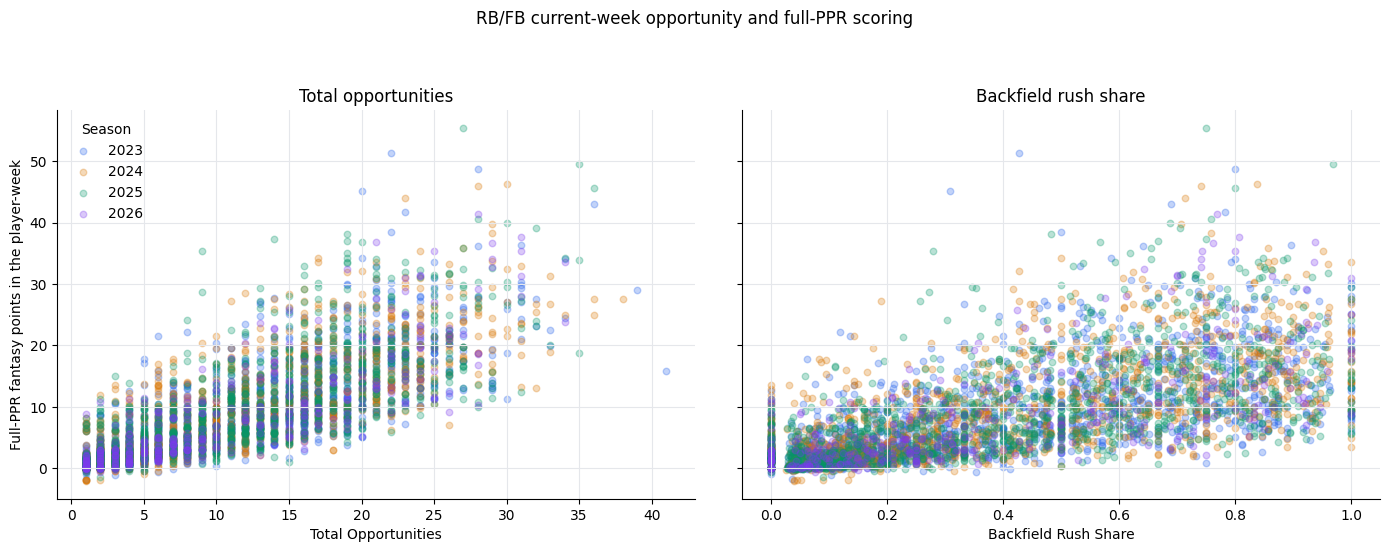

In [15]:
plot_population = gold_rb_weekly_trends.loc[
    gold_rb_weekly_trends["games_with_stat_record"].gt(0)
    & gold_rb_weekly_trends["total_opportunities"].gt(0)
    & gold_rb_weekly_trends["ppr_fantasy_points"].notna()
].copy()

season_colors = {2023: "#2563eb", 2024: "#d97706", 2025: "#059669", 2026: "#7C3AED"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for axis, (x_column, title) in zip(
    axes,
    [("total_opportunities", "Total opportunities"), ("backfield_rush_share", "Backfield rush share")],
):
    for season in SEASONS:
        season_rows = plot_population.loc[plot_population["season"].eq(season)]
        axis.scatter(
            season_rows[x_column].astype("float64"),
            season_rows["ppr_fantasy_points"].astype("float64"),
            label=str(season), color=season_colors[season], alpha=0.28, s=22,
        )
    axis.set_title(title)
    axis.set_xlabel(x_column.replace("_", " ").title())
    axis.grid(color="#e5e7eb", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Full-PPR fantasy points in the player-week")
axes[0].legend(title="Season", frameon=False, loc="upper left")
fig.suptitle("RB/FB current-week opportunity and full-PPR scoring", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.94], w_pad=3.0)
plt.show()

### 16. Persist season-partitioned Waiver Gold Parquet

Each partition is written and immediately reloaded. Shape, column order, dtypes, season membership, and grain must survive the round trip.

In [16]:
GOLD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_records = []
for season in SEASONS:
    season_partition = (
        gold_rb_weekly_trends.loc[gold_rb_weekly_trends["season"].eq(season)]
        .sort_values(["week", "display_name", "player_id"])
        .reset_index(drop=True)
    )
    output_path = GOLD_OUTPUT_DIR / f"rb_weekly_trends_{season}.parquet"
    season_partition.to_parquet(output_path, index=False)
    reloaded = pd.read_parquet(output_path)

    assert reloaded.shape == season_partition.shape
    assert reloaded.columns.tolist() == season_partition.columns.tolist()
    assert reloaded.dtypes.astype(str).tolist() == season_partition.dtypes.astype(str).tolist()
    assert set(reloaded["season"].unique()) == {season}
    assert not reloaded.duplicated(GOLD_GRAIN).any()

    output_records.append(
        {
            "dataset": "gold_rb_weekly_trends",
            "season": season,
            "rows": len(reloaded),
            "columns": len(reloaded.columns),
            "weeks": reloaded["week"].nunique(),
            "no_stat_rows": int(reloaded["games_with_stat_record"].eq(0).sum()),
            "grain": " + ".join(GOLD_GRAIN),
            "duplicate_grain_rows": reloaded.duplicated(GOLD_GRAIN).sum(),
            "file_mb": output_path.stat().st_size / 1024**2,
            "round_trip_passed": True,
        }
    )

output_summary = pd.DataFrame(output_records)

assert output_summary["rows"].sum() == len(gold_rb_weekly_trends)
assert output_summary["duplicate_grain_rows"].eq(0).all()
assert output_summary["round_trip_passed"].all()

output_summary

,dataset,season,rows,columns,weeks,no_stat_rows,grain,duplicate_grain_rows,file_mb,round_trip_passed
0,gold_rb_weekly_trends,2023,1847,99,18,277,player_id + season + week,0,0.213881,True
1,gold_rb_weekly_trends,2024,1849,99,18,223,player_id + season + week,0,0.214251,True
2,gold_rb_weekly_trends,2025,1846,99,18,187,player_id + season + week,0,0.214659,True
3,gold_rb_weekly_trends,2026,536,99,5,64,player_id + season + week,0,0.117523,True


In [17]:
print(
    f"Wrote {len(output_summary):,} RB/FB current-week Waiver Gold files with "
    f"{output_summary['rows'].sum():,} player-weeks, "
    f"{len(gold_rb_weekly_trends.columns):,} columns, and "
    f"{output_summary['file_mb'].sum():.2f} MB on disk."
)

Wrote 4 RB/FB current-week Waiver Gold files with 6,078 player-weeks, 99 columns, and 0.76 MB on disk.


## Takeaways

- `gold_rb_weekly_trends` contains **5,542 regular-season player-weeks and 99 columns** at `player_id + season + week`.
- All three season partitions cover Weeks 1–18 and preserve every contextual Silver player-week.
- **687 rows without weekly-stat evidence** retain null official production and fantasy scoring while canonical PBP opportunity remains observed zero.
- Current data contains no multi-team player-weeks. The schema still retains ordered game, team, and opponent context and will not falsely select a singular team if a future duplicate appears.
- Position-specific opportunity, share, efficiency, per-game, and full-PPR fields reconcile to the regular-season Silver inputs and pass Parquet round-trip checks.
- Calendar-week rolling windows, minimum-history flags, comparisons, and waiver signals remain intentionally unimplemented pending review of this foundation.